# O Algoritmo A* Bidirecional

#### Caio Sweiver de Carvalho
#### Renan José Silva Santos
#### Tiago Morroque Stresser dos Santos
#### Waldermar Serafim Neto

---
## 1. Resumo

## A* comum
No contexto de Teoria dos Grafos e Inteligência Artificial, encontrar o caminho mais curto entre dois pontos é um desafio de frequente utilização. O algoritmo **A* (ou A-Star)** resolve isso utilizando a seguinte função de avaliação:

$$f(x) = g(x) + h(x)$$

Onde:
* $g(x)$: É o **custo real** do caminho desde o nó inicial até o nó atual $x$.
* $h(x)$: É a **heurística**, uma estimativa do custo do nó atual $x$ até o destino final.

### A* Bidirecional
Em vez de buscarmos apenas do início para o fim, a busca **bidirecional** usa duas buscas simultâneas, uma partindo da origem e outra do destino, no caminho inverso.

Ou seja:
1.  **Busca Progressiva:** Parte da origem em direção ao destino.
2.  **Busca Regressiva:** Parte do destino em direção à origem.

Isso reduz drasticamente o tamanho da árvore de estados explorados, fazendo com que as duas buscas se encontrem no meio do caminho.

---
## 2. Exemplo: Rodovia da América do Norte
Para o nosso estudo de caso, modelamos um grafo que representa conexões entre grandes cidades da América do Norte.

Como a busca regressiva precisa partir do destino em sentido à origem, é preciso construir um grafo comum (`americaNorte`) e a sua versão transposta (`americaNorteInvertida`).

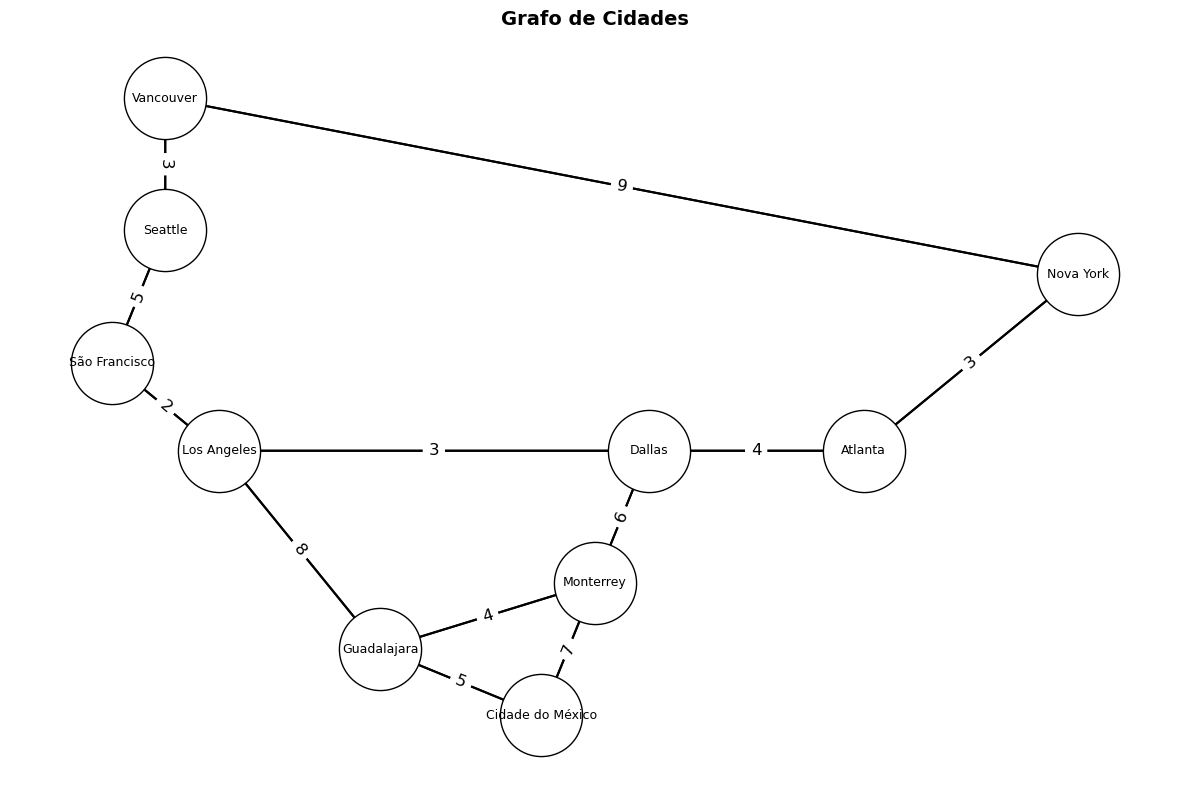

In [ ]:
import heapq
import matplotlib.pyplot as plt
import networkx as nx

# Definição do Grafo
americaNorte = {
    "Cidade do México": {"Guadalajara": 5, "Monterrey": 7},
    "Guadalajara": {"Cidade do México": 5, "Monterrey": 4, "Los Angeles": 8},
    "Monterrey": {"Cidade do México": 7, "Guadalajara": 4, "Dallas": 6},
    "Los Angeles": {"Guadalajara": 8, "Dallas": 3, "São Francisco": 2},
    "Dallas": {"Monterrey": 6, "Los Angeles": 3, "Atlanta": 4},
    "São Francisco": {"Los Angeles": 2, "Seattle": 5},
    "Seattle": {"São Francisco": 5, "Vancouver": 3},
    "Vancouver": {"Seattle": 3, "Nova York": 9},
    "Atlanta": {"Dallas": 4, "Nova York": 3},
    "Nova York": {"Atlanta": 3, "Vancouver": 9},
}

# Construção do grafo transposto
americaNorteInvertida = {node: {} for node in americaNorte}
for u in americaNorte:
    for v, cost in americaNorte[u].items():
        americaNorteInvertida[v][u] = cost

# Criação de um objeto na biblioteca de grafos
G = nx.DiGraph()

# Adiciona as arestas e os pesos
for cidade_origem, vizinhos in americaNorte.items():
    for cidade_destino, peso in vizinhos.items():
        G.add_edge(cidade_origem, cidade_destino, weight=peso)

# Posicionamento das cidades no plot (apenas para organização)
posicoes = {
    "Cidade do México": (0, -2),
    "Guadalajara": (-1.5, -1.25),
    "Monterrey": (0.5, -0.5),
    "Los Angeles": (-3, 1),
    "São Francisco": (-4, 2),
    "Dallas": (1, 1.0),
    "Seattle": (-3.5, 3.5),
    "Vancouver": (-3.5, 5),
    "Atlanta": (3, 1),
    "Nova York": (5, 3),
}

# Configuração do plot
plt.figure(figsize=(12, 8))
plt.title("Grafo de Cidades", fontsize=14, fontweight='bold')

# Vértices (cidades)
nx.draw_networkx_nodes(G, posicoes, node_size=3500, node_color='white', edgecolors='black')

# Arestas (vias)
nx.draw_networkx_edges(G, posicoes, arrowstyle="->", arrowsize=30, edge_color='black', width=1.5)

# Nomes
posicoes_labels = {k: (v[0], v[1]) for k, v in posicoes.items()}
nx.draw_networkx_labels(G, posicoes_labels, font_size=9)

# Pesos das arestas
pesos_arestas = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, posicoes, edge_labels=pesos_arestas, font_size=12, font_color='black')

plt.axis('off')

# Renderiza o grafo
plt.tight_layout()
plt.show()

---
## 2.1. Heurísticas ($h$)
Para uma heurística admissível, precisamos de estimativas de distância em linha reta para os dois fluxos:
* `hProgressiva`: Estima a distância de qualquer cidade até o nosso alvo final (`Nova York`).
* `hRegressivo`: Estima a distância de qualquer cidade de volta à nossa origem (`Cidade do México`).

In [ ]:
# Heurística do destino até a origem
hProgressiva = {
    "Cidade do México": 10, "Guadalajara": 8, "Monterrey": 7,
    "Los Angeles": 6, "Dallas": 5, "São Francisco": 5,
    "Seattle": 4, "Vancouver": 3, "Atlanta": 3, "Nova York": 0
}

# Heurística da origem até o destino
hRegressivo = {
    "Cidade do México": 0, "Guadalajara": 2, "Monterrey": 3,
    "Los Angeles": 4, "Dallas": 5, "São Francisco": 6,
    "Seattle": 7, "Vancouver": 8, "Atlanta": 6, "Nova York": 10
}

---

## 4. Implementação

Abaixo está a função principal do algoritmo, a `aEstrelaBidirecional`, no qual tem parâmetros `s` e `G`, tal qual `s` é a cidade de origem e `G` a de destino.

In [ ]:
def aEstrelaBidirecional(s, G):

    # Ambas as fronteiras como filas de prioridade.
    fronteiraProgressiva = []
    fronteiraRegressiva = []

    # Enfileira os nós iniciais com suas heurísticas.
    heapq.heappush(fronteiraProgressiva, (hProgressiva[s], s))
    heapq.heappush(fronteiraRegressiva, (hRegressivo[G], G))

    gProgressivo = {s: 0}
    gRegressivo = {G: 0}

    paiProgressivo = {s: None}
    paiRegressivo = {G: None}

    exploradosProgressivos = set()
    exploradosRegressivos = set()

    noEncontro = None
    melhorCusto = float("inf")

    while fronteiraProgressiva and fronteiraRegressiva:

        # Tira da fronteira o nó com menor f(x).
        _, noAtual = heapq.heappop(fronteiraProgressiva)

        # Adiciona o nó atual ao conjunto de nós explorados.
        exploradosProgressivos.add(noAtual)

        # Para cada vizinho do nó atual:
        for vizinho, cost in americaNorte[noAtual].items():

            # Calcula g(x) do vizinho.
            new_g = gProgressivo[noAtual] + cost

            # Se o vizinho não foi explorado ou se temos um caminho melhor para ele:
            if vizinho not in gProgressivo or new_g < gProgressivo[vizinho]:

                # Atualiza g(x) do vizinho.
                gProgressivo[vizinho] = new_g

                # Atualiza o pai do vizinho.
                paiProgressivo[vizinho] = noAtual

                # Calcula f(x) do vizinho.
                f_score = new_g + hProgressiva.get(vizinho, 0)

                # Adiciona o vizinho à fronteira.
                heapq.heappush(fronteiraProgressiva, (f_score, vizinho))

            # Se o vizinho já foi explorado na busca regressiva:
            if vizinho in exploradosRegressivos:

                # Calcula a soma dos custos g(x) das duas buscas.
                total = gProgressivo[vizinho] + gRegressivo[vizinho]

                # Se a soma for menor que o melhor custo:
                if total < melhorCusto:

                    # Temos um novo melhor custo.
                    melhorCusto = total

                    # E um novo nó de encontro.
                    noEncontro = vizinho

        # O mesmo processo é repetido para a busca regressiva, explorando, agora, a partir do nó G.

        _, noAtual = heapq.heappop(fronteiraRegressiva)
        exploradosRegressivos.add(noAtual)

        for vizinho, cost in americaNorteInvertida[noAtual].items():
            new_g = gRegressivo[noAtual] + cost

            if vizinho not in gRegressivo or new_g < gRegressivo[vizinho]:
                gRegressivo[vizinho] = new_g
                paiRegressivo[vizinho] = noAtual
                f_score = new_g + hRegressivo.get(vizinho, 0)
                heapq.heappush(fronteiraRegressiva, (f_score, vizinho))

            if vizinho in exploradosProgressivos:
                total = gProgressivo[vizinho] + gRegressivo[vizinho]
                if total < melhorCusto:
                    melhorCusto = total
                    noEncontro = vizinho

        if noEncontro and fronteiraProgressiva and fronteiraRegressiva:

            # Se a soma dos menores f(x) das duas fronteiras for maior ou igual ao melhor custo encontrado:
            if fronteiraProgressiva[0][0] + fronteiraRegressiva[0][0] >= melhorCusto:

                # A busca chega ao fim...
                break

    # Se as buscas não se encontraram, deu ruim.
    if noEncontro is None:
        return None, float("inf")

    # Reconstruindo o caminho a partir do nó de encontro.
    caminhoProgressivo = []
    node = noEncontro
    while node:
        caminhoProgressivo.append(node)
        node = paiProgressivo[node]
    caminhoProgressivo.reverse()

    caminhoRegressivo = []
    node = paiRegressivo[noEncontro]
    while node:
        caminhoRegressivo.append(node)
        node = paiRegressivo[node]

    caminhoCompleto = caminhoProgressivo + caminhoRegressivo

    return caminhoCompleto, melhorCusto

---
## 5. Teste Prático e Resultados
Dado a função principal do algoritmo, executamos `aEstrelaBidirecional` com **Cidade do México** como origem (`s`), e **Nova York** como destino (`G`).

In [ ]:
origem = "Cidade do México"
destino = "Nova York"

caminho, custo = aEstrelaBidirecional(origem, destino)

print("============ RESULTADO ============")
print(f"Origem: {origem} -> Destino: {destino}\n")
print("Melhor caminho encontrado:")
print(" -> ".join(caminho))
print("\nCusto mínimo total:", custo)

============ RESULTADO ============
Origem: Cidade do México -> Destino: Nova York

Melhor caminho encontrado:
Cidade do México -> Monterrey -> Dallas -> Atlanta -> Nova York

Custo mínimo total: 20


---
# Algoritmo A* Bidirecional - Exemplo maior

Para o exemplo em maior escala, houve a importação de bibliotecas de animação, como a `matplotlib.animation`, no qual só importamos a função de animação `FuncAnimation`, e `IPyhton.display` (`HTML`).

Também, é definida uma _seed_, pois neste exemplo, é usada uma randomização uniforme da posição dos vértices no grafo.

In [ ]:
import heapq
import random
import math
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

random.seed(42)

## 1. Geração dos vértices do grafo (cidades)
Criar um grafo de forma manual para um número muito grande de vértices é meio trabalhoso. Por isso, definimos `NUM_CIDADES = x` (neste caso sendo `100`) e espalhamos coordenadas geométricas $(X, Y)$ aleatoriamente no plano.

Para tornar a simulação realista, cada cidade se conecta estritamente às **4 cidades vizinhas mais próximas**. O custo das arestas ($g(v)$) será a distância euclidiana de $u$ até $v$.

In [ ]:
NUM_CIDADES = 100
posicoes = {}

# Vértice de origem e destino ficam nos dois pontos extremos do mapa
origem = 0
destino = NUM_CIDADES - 1
posicoes[origem] = (0.0, 5.0)
posicoes[destino] = (10.0, 5.0)

# Distribui as cidades
for i in range(1, NUM_CIDADES - 1):
    x = random.uniform(0.5, 9.5)
    y = random.uniform(0.0, 10.0)
    posicoes[i] = (x, y)

# Inicializa a estrutura do grafo
pais = {i: {} for i in range(NUM_CIDADES)}

def calcular_distancia(p1, p2):
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)

# Conecta aos 4 vizinhos mais próximos
K_VIZINHOS = 4
for i in range(NUM_CIDADES):
    distancias = []
    for j in range(NUM_CIDADES):
        if i != j:
            d = calcular_distancia(posicoes[i], posicoes[j])
            distancias.append((d, j))
    distancias.sort()
    for d, vizinho in distancias[:K_VIZINHOS]:
        pais[i][vizinho] = round(d, 2)

# Grafo invertido para a busca regressiva
paisInvertido = {node: {} for node in pais}
for u in pais:
    for v, cost in pais[u].items():
        paisInvertido[v][u] = cost

## 2. Definição das Heurísticas Admissíveis
Para a admissibilidade da heurística, foi usado a distância euclidiana entre as cidades, como usado no primeiro exemplo.

Ou seja, para cada ponto de partida (progressiva ou regressiva), temos:
* A `hProgressiva` calcula a distância em linha reta de qualquer vértice até o destino.
* A `hRegressivo` calcula a distância em linha reta de qualquer vértice até a origem.

In [ ]:
hProgressiva = {i: round(calcular_distancia(posicoes[i], posicoes[destino]), 2) for i in range(NUM_CIDADES)}
hRegressivo = {i: round(calcular_distancia(posicoes[i], posicoes[origem]), 2) for i in range(NUM_CIDADES)}

## 3. Função de busca
Nesta etapa, implementamos a função de busca. Ela alterna iterações expandindo a fronteira que sai da origem e a fronteira que sai do destino.

A cada vértice visitado, o estado do conjunto de vértices `explorados` é salvo na lista de `historico_passos`, que posteriormente serve para representar, o passo a passo da busca, visualmente com a animação do matplotlib.

In [ ]:
def obter_passos_animacao(s, G):
    fronteiraProgressiva, fronteiraRegressiva = [], []
    heapq.heappush(fronteiraProgressiva, (hProgressiva[s], s))
    heapq.heappush(fronteiraRegressiva, (hRegressivo[G], G))

    gProgressivo, gRegressivo = {s: 0}, {G: 0}
    paiProgressivo, paiRegressivo = {s: None}, {G: None}
    exploradosProgressivos, exploradosRegressivos = set(), set()

    historico_passos = []
    noEncontro = None
    melhorCusto = float("inf")
    passo_contador = 0

    while fronteiraProgressiva and fronteiraRegressiva:
        # Registra o estado no início da iteração para a animação
        historico_passos.append((set(exploradosProgressivos), set(exploradosRegressivos), noEncontro))
        passo_contador += 1

        # Busca progressiva
        _, noAtual = heapq.heappop(fronteiraProgressiva)
        exploradosProgressivos.add(noAtual)

        for vizinho, cost in pais[noAtual].items():
            new_g = gProgressivo[noAtual] + cost
            if vizinho not in gProgressivo or new_g < gProgressivo[vizinho]:
                gProgressivo[vizinho] = new_g
                paiProgressivo[vizinho] = noAtual
                heapq.heappush(fronteiraProgressiva, (new_g + hProgressiva[vizinho], vizinho))
            if vizinho in exploradosRegressivos:
                if gProgressivo[vizinho] + gRegressivo[vizinho] < melhorCusto:
                    melhorCusto = gProgressivo[vizinho] + gRegressivo[vizinho]
                    noEncontro = vizinho

        # Busca regressiva
        _, noAtual = heapq.heappop(fronteiraRegressiva)
        exploradosRegressivos.add(noAtual)

        for vizinho, cost in paisInvertido[noAtual].items():
            new_g = gRegressivo[noAtual] + cost
            if vizinho not in gRegressivo or new_g < gRegressivo[vizinho]:
                gRegressivo[vizinho] = new_g
                paiRegressivo[vizinho] = noAtual
                heapq.heappush(fronteiraRegressiva, (new_g + hRegressivo[vizinho], vizinho))
            if vizinho in exploradosProgressivos:
                if gProgressivo[vizinho] + gRegressivo[vizinho] < melhorCusto:
                    melhorCusto = gProgressivo[vizinho] + gRegressivo[vizinho]
                    noEncontro = vizinho

        # 'Caso base'
        if noEncontro and fronteiraProgressiva and fronteiraRegressiva:
            if fronteiraProgressiva[0][0] + fronteiraRegressiva[0][0] >= melhorCusto:
                break

    # Estado final
    historico_passos.append((set(exploradosProgressivos), set(exploradosRegressivos), noEncontro))

    # 'Caminho final'
    caminhoProgressivo = []
    node = noEncontro
    while node is not None:
        caminhoProgressivo.append(node)
        node = paiProgressivo.get(node)
    caminhoProgressivo.reverse()

    caminhoRegressivo = []
    if noEncontro != G:
        node = paiRegressivo.get(noEncontro)
        while node is not None:
            caminhoRegressivo.append(node)
            node = paiRegressivo.get(node)

    return historico_passos, caminhoProgressivo + caminhoRegressivo

# Execução da função
passos, caminho_final = obter_passos_animacao(origem, destino)

## 4. Visualização do grafo e animação
Com a biblioteca `NetworkX`, criamos um grafo e adicionamos todas as arestas presentes e usamos a função `atualizar(frame)` (implementada na próxima célula) dentro da função `FuncAnimation` do `Matplotlib`.

A função `HTML(ani.to_jshtml())` converte o tipo do `ani` (arquivo de mídia) para HTML, que é suportado pelo Jupyter.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))
G_nx = nx.Graph()
for u in pais:
    for v in pais[u]:
        G_nx.add_edge(u, v)

# Função a ser passada para FuncAnimation (do matplotlib)
def atualizar(frame):
    ax.clear()
    ax.set_title(f"A* Bidirecional", fontsize=12, fontweight='bold')
    ax.axis('off')

    explorados_prog, explorados_reg, encontro = passos[frame]

    cores_nos = []
    tamanhos_nos = []

    # Cores e tamanhos de cada tipo de nó
    for no in G_nx.nodes():
        if no == origem:
            cores_nos.append('cyan')
            tamanhos_nos.append(200)
        elif no == destino:
            cores_nos.append('magenta')
            tamanhos_nos.append(200)
        elif no == encontro:
            cores_nos.append('gold')
            tamanhos_nos.append(60)
        elif no in explorados_prog:
            cores_nos.append('lightgreen')
            tamanhos_nos.append(60)
        elif no in explorados_reg:
            cores_nos.append('salmon')
            tamanhos_nos.append(60)
        else:
            cores_nos.append('#ECECEC')
            tamanhos_nos.append(20)

    # Nós do grafo
    nx.draw_networkx_nodes(G_nx, posicoes, node_size=tamanhos_nos, node_color=cores_nos, edgecolors='black', linewidths=0.4, ax=ax)
    nx.draw_networkx_edges(G_nx, posicoes, edge_color='#E0E0E0', width=0.5, alpha=0.7, ax=ax)

    # Caminho ótimo adiquirido
    if frame == len(passos) - 1:
        arestas_caminho = [(caminho_final[i], caminho_final[i+1]) for i in range(len(caminho_final)-1)]
        nx.draw_networkx_edges(G_nx, posicoes, edgelist=arestas_caminho, edge_color='blue', width=2.5, ax=ax)

    labels = {origem: "origem", destino: "destino"}
    pos_labels = {k: (v[0], v[1] + 0.3) for k, v in posicoes.items() if k in labels}
    nx.draw_networkx_labels(G_nx, pos_labels, labels=labels, font_size=9, font_weight='bold', ax=ax)

# Chamada da função de animação do matplotlib
ani = FuncAnimation(fig, atualizar, frames=len(passos), interval=300, repeat=False)
plt.close()

# Player
HTML(ani.to_jshtml())

## Referências

MATPLOTLIB. **matplotlib.animation.FuncAnimation**. Disponível em: https://matplotlib.org/stable/api/_as_gen/matplotlib.animation.FuncAnimation.html. Acesso em: 22 jun. 2026.

NETWORKX. **Hantavirus**. Disponível em: https://networkx.org/nx-guides/content/applications/hantavirus.html. Acesso em: 22 jun. 2026.